# CT Reconstruction Filter Comparison

## Objective

Compare FBP reconstruction filters using image quality metrics and visual inspection.

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.transform import iradon, radon

from medimaging.quality.evaluation import evaluate_image_quality
from medimaging.simulation.phantom import create_shepp_logan

## Paso 2. Preparar la adquisición

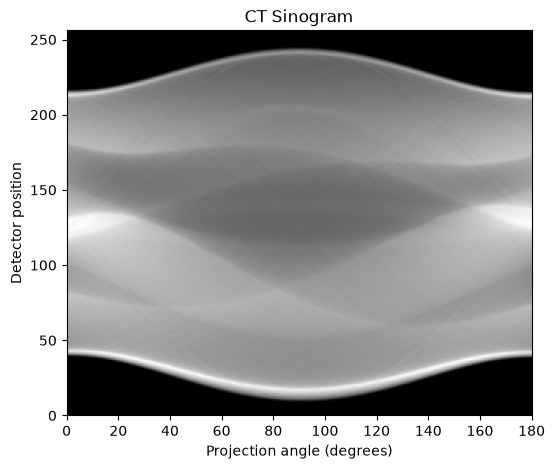

In [3]:
phantom = create_shepp_logan(256)

n_projections = 180
theta = np.linspace(
    0.0,
    180.0,
    n_projections,
    endpoint=False,
)

sinogram = radon(
    phantom,
    theta=theta,
    circle=True,
)

plt.figure(figsize=(6, 5))
plt.imshow(
    sinogram,
    cmap="gray",
    aspect="auto",
    extent=(0, 180, 0, sinogram.shape[0]),
)
plt.title("CT Sinogram")
plt.xlabel("Projection angle (degrees)")
plt.ylabel("Detector position")
plt.show()

## Paso 3. Reconstruir con diferentes filtros

In [4]:
filter_names = [
    "ramp",
    "shepp-logan",
    "cosine",
    "hann",
    "hamming",
]

results = []
reconstructions = {}

for filter_name in filter_names:
    start_time = time.perf_counter()

    reconstruction = iradon(
        sinogram,
        theta=theta,
        filter_name=filter_name,
        circle=True,
    )

    elapsed_time = time.perf_counter() - start_time
    metrics = evaluate_image_quality(reference=phantom, image=reconstruction,)
    reconstructions[filter_name] = reconstruction

    results.append(
        {
            "filter": filter_name,
            "psnr": metrics["psnr"],
            "ssim": metrics["ssim"],
            "mae": metrics["mae"],
            "rmse": metrics["rmse"],
            "reconstruction_time": elapsed_time,
        }
    )

results_df = pd.DataFrame(results)
results_df

,filter,psnr,ssim,mae,rmse,reconstruction_time
0,ramp,30.774608,0.921829,0.011409,0.028925,0.075478
1,shepp-logan,29.879193,0.941527,0.011070,0.032066,0.050514
2,cosine,28.179924,0.960527,0.011016,0.038995,0.045187
3,hann,26.846327,0.957948,0.012433,0.045466,0.044115
4,hamming,27.134425,0.958476,0.012211,0.043982,0.047203


## Paso 4. Visualizar las reconstrucciones

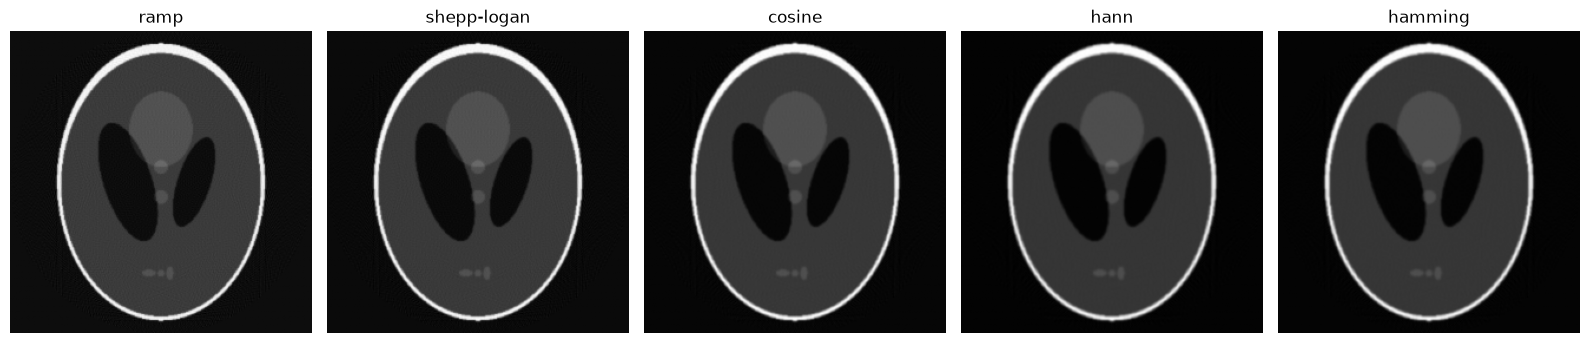

In [4]:
fig, axes = plt.subplots(
    1,
    len(filter_names),
    figsize=(16, 4),
)

for ax, filter_name in zip(axes, filter_names, strict=True):
    ax.imshow(
        reconstructions[filter_name],
        cmap="gray",
    )
    ax.set_title(filter_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Paso 5. Comparar PSNR y SSIM

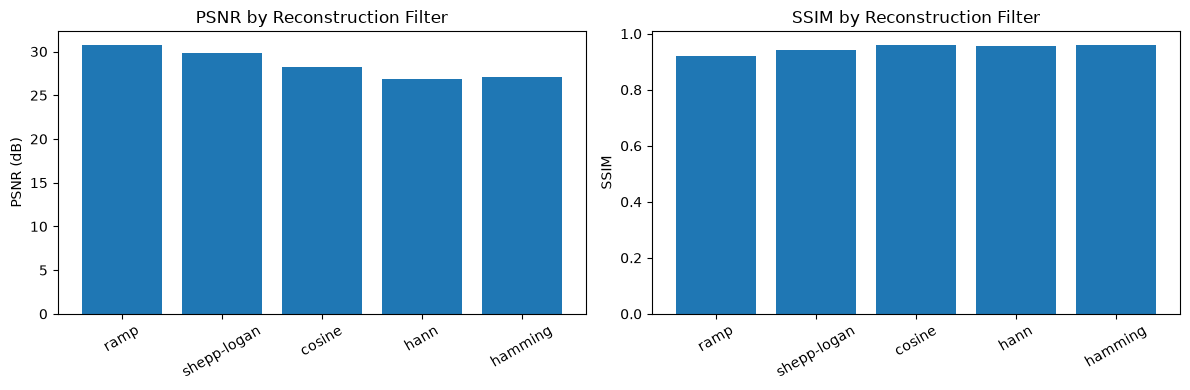

In [5]:
filter_labels = [result["filter"] for result in results]
psnr_values = [result["psnr"] for result in results]
ssim_values = [result["ssim"] for result in results]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(filter_labels, psnr_values)
axes[0].set_title("PSNR by Reconstruction Filter")
axes[0].set_ylabel("PSNR (dB)")
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(filter_labels, ssim_values)
axes[1].set_title("SSIM by Reconstruction Filter")
axes[1].set_ylabel("SSIM")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Paso 6. Comparar el tiempo de reconstrucción

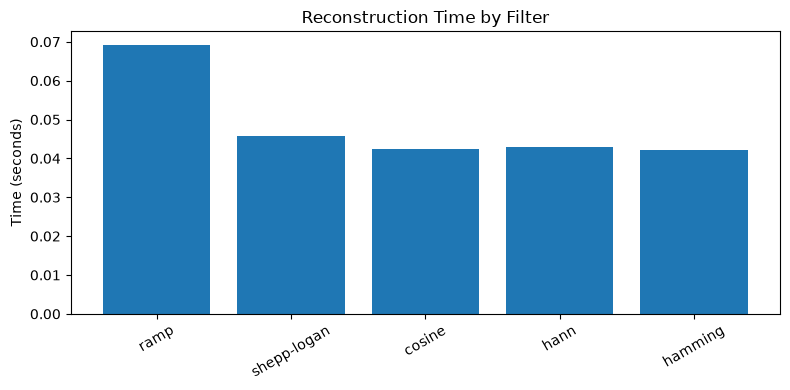

In [6]:
time_values = [
    result["reconstruction_time"]
    for result in results
]

plt.figure(figsize=(8, 4))
plt.bar(filter_labels, time_values)
plt.title("Reconstruction Time by Filter")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Conclusions

The reconstruction filter affected both image quality metrics and execution time.

The ramp filter achieved the highest PSNR (30.77 dB), while the cosine filter achieved the highest SSIM (0.9605). This difference shows that pixel-wise error and structural similarity do not necessarily identify the same filter as optimal.

The most suitable filter depends on image characteristics and the intended application. Further experiments with noisy projection data are needed to evaluate the trade-off between detail preservation and noise suppression.

Four image quality metrics were used to compare five FBP reconstruction filters.

The ramp filter achieved the highest PSNR and lowest RMSE, while the cosine filter achieved the highest SSIM and lowest MAE. These results demonstrate that image quality metrics capture different aspects of reconstruction error and structural similarity.

Filter selection depends on the evaluation objective and acquisition conditions. These findings are limited to the simulated Shepp–Logan phantom.